# Exercise 1

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Read the CSV file into a DataFrame
df = pd.read_csv("CO2data.csv") # læser CSV-filen ind i en DataFrame

# Extract the features and target variable
X = df[['Weight', 'Volume']].values # udtrækker vægt og volumen som features
y = df['CO2'].values # udtrækker CO2 som target variable

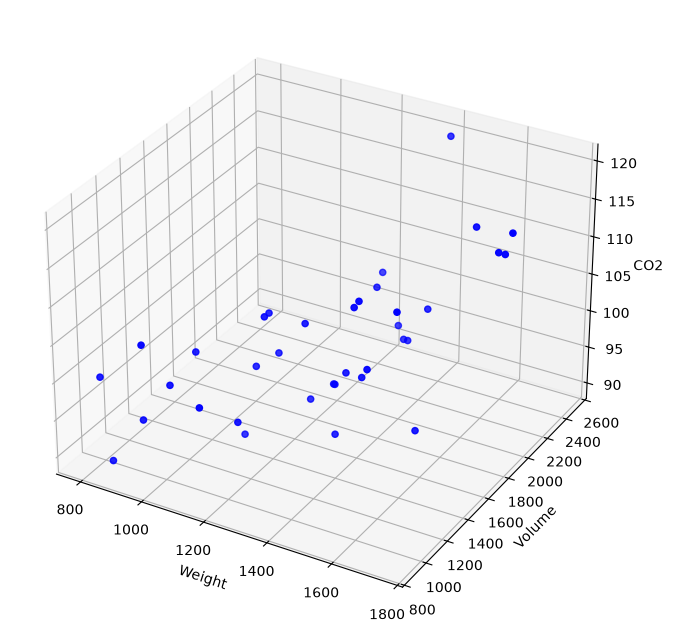

In [72]:
# Visualize the original data
fig = plt.figure(figsize=(10, 8)) # opretter en figur med specificeret størrelse
ax = fig.add_subplot(111, projection='3d') # tilføjer et 3D subplot til figuren

# Scatter plot of 'Weight,' 'Volume,' and 'CO2'
ax.scatter(X[:, 0], X[:, 1], y, c='b', marker='o') # opretter et scatter plot i 3D med vægt, volumen og CO2

# Set labels for axes
ax.set_xlabel('Weight') # sætter label for x-aksen
ax.set_ylabel('Volume') # sætter label for y-aksen
ax.set_zlabel('CO2') # sætter label for z-aksen

plt.show() # viser figuren med scatter plot i 3D

In [73]:
# How well does the features perform individually?
'''featuresene som volumen, vægt og CO2 bruges til at forudsige '''

# Create a linear regression model
model = LinearRegression() # initialiserer en lineær regressionsmodel
train = model.fit(X, y) # træner modellen på alle features og matcher input med target
y_pred = model.predict(X) # forudsiger CO2-udledning baseret på alle features
mse = mean_squared_error(y, y_pred) # beregner mean squared error mellem de faktiske og forudsagte værdier
print("MSE for alle features:", mse) # udskriver MSE for modellen baseret på alle features

# Train a model based on weight and calculate mse
train_weight = model.fit(df[['Weight']], y) # træner modellen på vægt og matcher input med target
pred_weight = model.predict(df[["Weight"]]) # forudsiger CO2-udledning baseret på vægt
mse = mean_squared_error(y, pred_weight) # beregner mean squared error mellem de faktiske og forudsagte værdier
print("MSE for vægt:", mse) # udskriver MSE for modellen baseret på vægt

# Train a model based on volume and calculate mse
train_volume = model.fit(df[['Volume']], y) # træner modellen på volumen og matcher input med target
pred_volume = model.predict(df[['Volume']]) # forudsiger CO2-udledning baseret på volumen
mse_volume = mean_squared_error(y, pred_volume) # beregner mean squared error mellem de faktiske og forudsagte værdier
print("MSE for volumen:", mse_volume) # udskriver MSE for modellen baseret på volumen

MSE for alle features: 33.68279098995154
MSE for vægt: 37.55581115956569
MSE for volumen: 35.08725287919057


In [74]:
# Train a model based on both features and calculate mse
model = LinearRegression() # initialiserer en lineær regressionsmodel

train_weight_volume = model.fit(df[['Weight', 'Volume']], y) # træner modellen på inputdata og matcher input med target
pred_weight_volume = model.predict(df[['Weight', 'Volume']]) # forudsiger CO2-udledning for givet vægt og volumen
mse = mean_squared_error(y, pred_weight_volume) # beregner mean squared error mellem de faktiske og forudsagte værdier
print("MSE for vægt og volumen:", mse) # udskriver MSE for modellen baseret på vægt og volumen

MSE for vægt og volumen: 33.68279098995154


In [75]:
# Predict the CO2 emission of car where the weight is 2300kg and the volume is 1300cm3
model = LinearRegression() # initialiserer en lineær regressionsmodel
train_weight_volume = model.fit(X, y) # træner modellen på inputdata og matcher input med target
pred_weight_volume = model.predict([[2300, 1300]]) # forudsiger CO2-udledning for givet vægt og volumen
print("Forudsagt CO2-udledning:", pred_weight_volume) # udskriver den forudsagte CO2-udledning

Forudsagt CO2-udledning: [107.2087328]


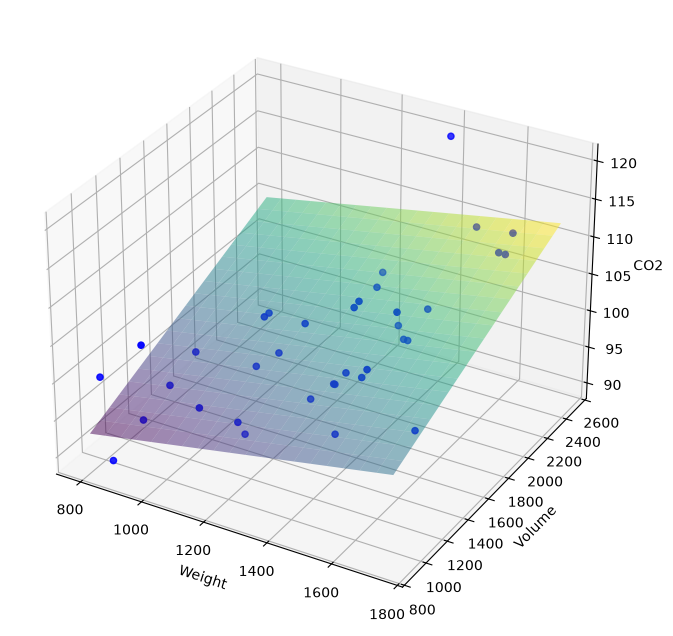

In [76]:
# Visualize the regression plane
fig = plt.figure(figsize=(10, 8)) # opretter en ny figur med specificeret størrelse
axis = fig.add_subplot(111, projection='3d') # tilføjer et 3D subplot til figuren

# Scatter plot for det aktuelle data
axis.scatter(X[:, 0], X[:, 1], y, c='b', marker='o', label='Aktuel Data') # scatter plot for det aktuelle data

# Skab et mesh gitter for planet (regressionsfladen)
x_grid, y_grid = np.meshgrid(np.linspace(X[:, 0].min(), X[:, 0].max(), 20), 
                             np.linspace(X[:, 1].min(), X[:, 1].max(), 20)) # opretter et mesh gitter for x- og y-aksen
z_grid = model.intercept_ + model.coef_[0] * x_grid + model.coef_[1] * y_grid  # beregner z-værdierne for regressionsplanet

# Plot regression planet
axis.plot_surface(x_grid, y_grid, z_grid, cmap='viridis', alpha=0.5) # plot regression planet

# Lav labels til axis og titel for 3D plottet
axis.set_xlabel('Weight') # sætter label for x-aksen
axis.set_ylabel('Volume') # sætter label for y-aksen
axis.set_zlabel('CO2') # sætter label for z-aksen

# Vis plottet
plt.show() # viser 3D plottet



# Exercise 2


In [77]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Read the CSV file into a DataFrame
df = pd.read_csv("CVDdata.csv")

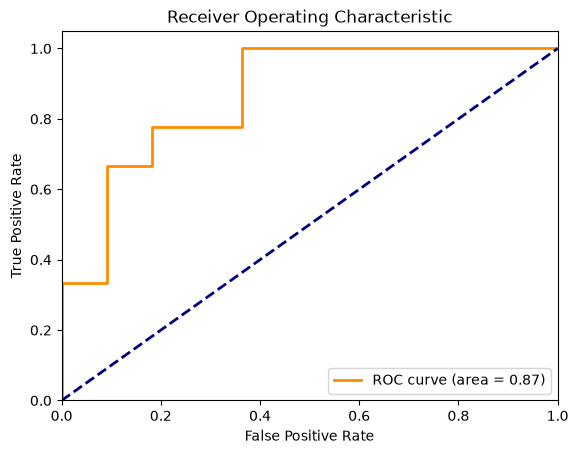

In [78]:
# Define input and target
X = df[['BP']].values # Using only blood pressure
#X = df[['BP','Smoking']].values # Using blood pressure and smoking
y = df['CVD'].values

# Define the model
logreg = LogisticRegression() # initialiserer en logistisk regressionsmodel

# Fit model
logreg.fit(X, y) # træner modellen på inputdata og matcher input med target

# Predict probabilities
y_pred = logreg.predict_proba(X)[:, 1] # forudsiger sandsynligheden for positiv klasse (CVD)

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y, y_pred) # fpr er false positive rate, tpr er true positive rate og thresholds er tærskelværdierne

# Calculate the area under the ROC curve (AUC)
roc_auc = auc(fpr, tpr) # beregner arealet under ROC-kurven (AUC)

# Plot the ROC curve
plt.figure() # opretter en ny figur til plotning
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc) # plotter ROC-kurven med AUC i legend 
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # plotter diagonal linje som reference for tilfældig klassifikation
plt.xlim([0.0, 1.0]) # sætter x-akse grænser fra 0 til 1
plt.ylim([0.0, 1.05]) # sætter y-akse grænser fra 0 til 1.05
plt.xlabel('False Positive Rate') # sætter label for x-aksen
plt.ylabel('True Positive Rate') # sætter label for y-aksen
plt.title('Receiver Operating Characteristic') # sætter titel for grafen
plt.legend(loc="lower right") # viser legend på grafen

plt.show()
